# Step 2-3. 내 Multi-Agent 서비스 만들기
Step 2-1, 2-2에서는 신약 검토 팀을 따라 만들었습니다. 이번에는 **내 주제로 팀을 만들고 서비스로 띄웁니다.**

전문가 목록만 적으면 지휘자(고르기, 동시에 시키기, 합치기)는 `agent_team.py`가 맡습니다. Step 2-2에서 직접 짠 코드를 다시 쓸 수 있게 묶어 둔 것입니다.

## 순서
1. 완성 예시를 돌려 본다: **흉부 엑스레이 판독 보조 팀** (1일차의 사진 검색을 Multi-Agent로 다시 만든 것)
2. 팀이 무엇으로 이루어지는지 본다: 도구, 전문가, 기초 자료
3. 내 팀을 만든다 (건강검진 상담 팀 예시를 고쳐서)
4. 웹 화면과 Kiro에서 쓴다

## 핵심 개념
- **Tool(도구)**: 평범한 파이썬 함수. 설명글을 보고 Agent가 언제 쓸지 정합니다
- **Expert(전문가)**: 지시문과 도구를 가진 Agent 한 명
- **Orchestrator(지휘자)**: 질문마다 전문가를 고르고 답을 합치는 역할

In [1]:
# 필요한 패키지를 설치합니다. 처음에는 1~2분 걸립니다.
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "ollama", "strands-agents[ollama]", "numpy", "requests", "rdkit"], check=True)
print("✅ 패키지 준비 완료. 다음 셀로 넘어가세요.")

✅ 패키지 준비 완료. 다음 셀로 넘어가세요.


## 1. 완성 예시: 흉부 엑스레이 판독 보조 팀
먼저 팀을 불러옵니다. 저장소 맨 위의 `xray_team.py`에 들어 있습니다.

In [2]:
import os, sys, warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))     # 저장소 맨 위의 파일들을 불러오기 위해
import ollama
import xray_team
from agent_team import EXPERT_MODEL

installed = [m.model for m in ollama.list().models]
for name in [EXPERT_MODEL, "bge-m3"]:
    if not any(m == name or m.startswith(name + ":") for m in installed):
        print(f"⬇️  {name} 내려받는 중... (처음 한 번만)")
        ollama.pull(name)
team = xray_team.TEAM
print(f"✅ {team.goal} 준비 완료  (모델: {EXPERT_MODEL})")
for key, e in team.experts.items():
    print(f"   {key:<11} {e['title']:<14} 도구: {', '.join(t.tool_name for t in e['tools'])}")

✅ 흉부 엑스레이 판독을 돕는 팀 준비 완료  (모델: gemma4:e4b)
   reader      영상 판독 보조 전문가   도구: look_at_image
   cases       유사 사례 전문가      도구: search_similar_cases
   literature  문헌 전문가         도구: pubmed_search


검토할 사진을 봅니다. 모두 공개 라이선스 사진입니다(`data/xray/SOURCES.md`). **실제 환자 사진은 넣지 않습니다.**

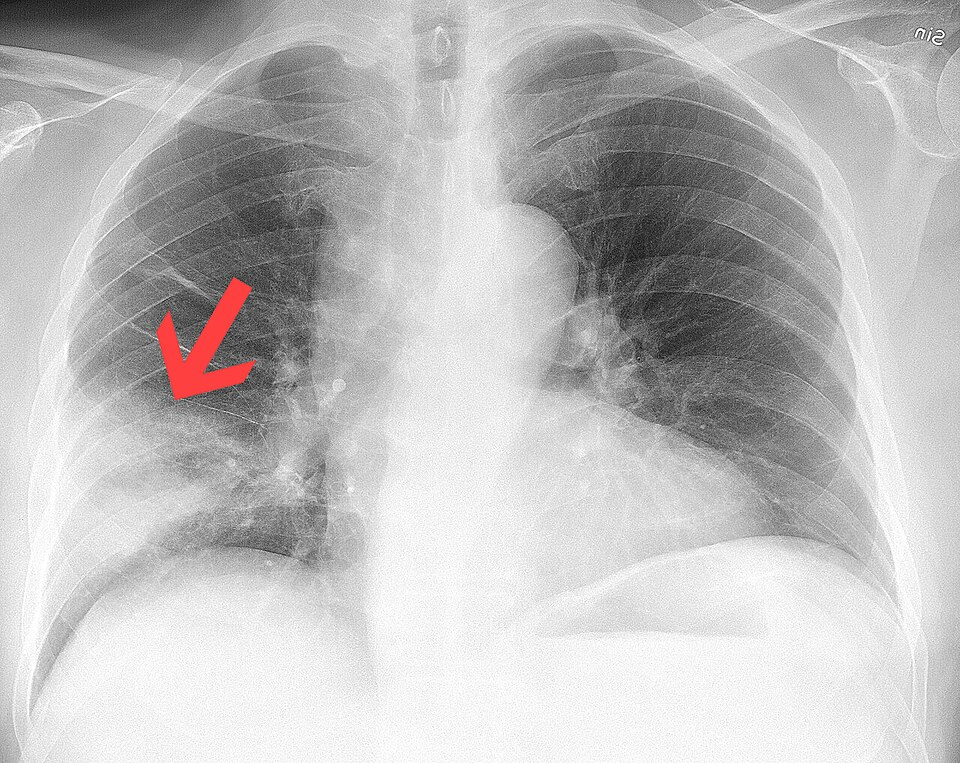

In [3]:
from IPython.display import Image, display

# TODO: 다른 사진으로 바꿔 보세요! normal_pa.jpg, heart_failure.jpg, pneumothorax.png, rib_fracture.jpg, tuberculosis.jpg
CASE = "lobar_pneumonia.jpg"
display(Image(filename=f"../data/xray/{CASE}", width=380))

이제 팀에게 묻습니다. 전문가 세 명이 **동시에** 일하고 지휘자가 합칩니다. 1\~2분 걸립니다.

- 영상 판독 보조 전문가: 사진을 다시 봅니다 (Vision 모델)
- 유사 사례 전문가: 사람이 판독 요약을 붙여 둔 사례 모음에서 비슷한 것을 찾습니다
- 문헌 전문가: PubMed에서 논문을 찾습니다

In [4]:
result = team.ask("이 사진을 종합적으로 검토해 줘", case=CASE)

👤 질문: 이 사진을 종합적으로 검토해 줘   (대상: lobar_pneumonia.jpg)
🧭 고른 전문가: 영상 판독 보조 전문가, 유사 사례 전문가, 문헌 전문가  (고르는 데 2.23초)
⏳ 전문가 3명이 동시에 일하는 중입니다. 한 명에 30초~1분쯤 걸립니다.
   ✅ 1/3 유사 사례 전문가 끝  (80초)
   ✅ 2/3 문헌 전문가 끝  (91초)
   ✅ 3/3 영상 판독 보조 전문가 끝  (104초)

🧑‍🔬 영상 판독 보조 전문가  (103.5초, 도구: look_at_image)
### 흉부 엑스레이 검토 결과

**1. 폐야 밀도 비교**
오른쪽 폐야가 왼쪽 폐야에 비해 전반적으로 더 높은 음영(density)을 보입니다.

**2. 국소 음영 관찰**
오른쪽 폐의 중앙부와 아래쪽 영역에 불규칙하게 뭉쳐진 듯한 음영이 관찰됩니다. 이 음영은 특정 부위에 집중되어 있는 양상입니다.

**3. 결론적 소견**
오른쪽 폐에 국한된 음영 증가가 있으며, 이는 좌측 폐와 대비됩니다.

확신 정도: 높음

🧑‍🔬 유사 사례 전문가  (80.0초, 도구: search_similar_cases)
**유사 사례 분석**
검색된 3건의 사례 중, 오른쪽 폐의 침윤 소견과 가장 유사한 것은 `pneumonia_2.jpg` (폐렴, 0.596)입니다.

**유사점과 차이점**
유사한 점은 모두 오른쪽 폐에 음영이 관찰된다는 점입니다. 그러나 기초 자료의 '특정 부위에 집중된 불규칙한 음영'은 `pneumonia_2.jpg`의 '여러 군데 얼룩덜룩한 경화'와 패턴이 다릅니다. 또한, `pleural_effusion.jpg`는 흉수(흉강 내 액체)를, `tuberculosis.jpg`는 양쪽 폐 침윤 및 공동을 보여 패턴이 다릅니다.

**종합 소견**
제시된 소견은 폐 실질 내의 국소적인 염증성 병변(폐렴)을 시사하며, 유사 사례들은 폐렴, 흉수, 결핵 등 다양한 원인으로 오른쪽 폐에 병변이 있는 경우입니다. 유사도는 보통 수준으로 판단됩니다.

보통

🧑‍

### 정답과 비교하기
이 사진에는 사람이 쓴 판독 요약이 있습니다. AI의 답과 견줘 보세요. **위치나 소견이 다르게 나오는 일이 흔합니다.** 그래서 이 팀의 이름이 "판독"이 아니라 "판독 보조"이고, 마지막 항목이 "사람이 꼭 확인할 것"입니다.

In [5]:
truth = next(c for c in xray_team.LIBRARY if c["file"] == CASE)
print(f"사람이 쓴 판독 요약: [{truth['label']}] {truth['summary']}")

사람이 쓴 판독 요약: [폐렴 (대엽성)] 67세 남성. 오른쪽 폐 중엽에 경화(하얗게 채워진 음영)가 보이는 대엽성 폐렴. 사진의 빨간 화살표가 병변 위치.


## 2. 팀은 무엇으로 이루어지나
`xray_team.py`를 왼쪽 파일 목록에서 열어 보세요. 세 가지뿐입니다.

| 무엇 | 엑스레이 팀에서는 | 코드 |
|---|---|---|
| **도구** | 사진 다시 보기, 비슷한 사례 찾기, 논문 찾기 | 파이썬 함수 3개 |
| **전문가** | 누가 어떤 도구를 쓰는지, 무슨 일을 맡는지 | `Team(experts={...})` |
| **기초 자료** | 모든 전문가가 함께 보는 사진 설명 | `prepare` 함수 |

지휘자는 전문가의 `role`(맡는 일) 설명만 보고 누구에게 보낼지 고릅니다. 아래가 지휘자에게 실제로 주는 지시문입니다.

In [ ]:
print(team.router_prompt)
print()
# TODO: 질문을 바꿔 보세요! 누구에게 보내는지만 확인합니다 (1초)
for q in ["심장이 커 보이는지 사진을 봐 줘", "이 사진과 비슷한 과거 사례가 있어?", "기흉이 의심되면 어떤 추가 검사를 하는지 논문을 찾아 줘", "판독 전에 참고할 내용을 전부 정리해 줘"]:
    print(f"{q:<44} → {team.route_with_teacher(q)}")

## 3. 내 팀 만들기
아래 셀은 `my_team.py` 파일을 만듭니다. **건강검진 결과 상담 팀**이 예시로 들어 있어 그대로 실행해도 됩니다.

내 주제로 바꿀 때는 이 순서로 고칩니다.

1. **도구**: 전문가가 근거를 찾을 함수를 씁니다. 계산, 표 조회, 파일 읽기, 공개 API 조회 무엇이든 됩니다. 함수 바로 아래 설명글이 중요합니다
2. **전문가**: `role`은 서로 겹치지 않게 씁니다. 겹치면 지휘자가 헷갈립니다
3. **질문 틀**: Step 2-4의 증류에 씁니다. 지금은 그대로 두어도 됩니다

> 주제 예: 복약 상담(약 정보, 상호작용, 문헌), 임상시험 찾기(환자 조건, 시험 검색, 문헌), 논문 리뷰(방법, 통계, 선행 연구)

In [6]:
%%writefile ../my_team.py
"""내 Multi-Agent 팀. 노트북 2-3의 셀에서 만들어지는 파일이다. (예시: 건강검진 결과 상담 팀)

바꾸는 순서: ① 도구(파이썬 함수) → ② 전문가(누가 어떤 도구를 쓰는지) → ③ 질문 틀(증류용)
교육·연구용이며 진료나 임상 판단을 대신하지 않는다.
"""
import drug_tools as dt
from agent_team import Team

# ---------- ① 도구: 평범한 파이썬 함수. 설명글(docstring)을 보고 Agent가 언제 쓸지 정한다 ----------
# 교육용 예시 기준이다. (경계값 미만이면 그 판정, 모두 넘으면 마지막 판정)
RANGES = {
    "공복혈당": ("mg/dL", [(100, "정상"), (126, "당뇨병 전단계(공복혈당장애)")], "당뇨병 의심"),
    "당화혈색소": ("%", [(5.7, "정상"), (6.5, "당뇨병 전단계")], "당뇨병 의심"),
    "수축기혈압": ("mmHg", [(120, "정상"), (140, "주의·고혈압 전단계")], "고혈압 의심"),
    "총콜레스테롤": ("mg/dL", [(200, "정상"), (240, "경계")], "높음"),
    "LDL콜레스테롤": ("mg/dL", [(130, "정상"), (160, "경계")], "높음"),
}


def check_value(item: str, value: float) -> dict:
    """검사 수치 하나가 정상 범위인지 판정한다. item은 공복혈당, 당화혈색소, 수축기혈압, 총콜레스테롤, LDL콜레스테롤 중 하나."""
    key = next((k for k in RANGES if k.lower() in item.replace(" ", "").lower()), None)
    if key is None:
        return {"error": f"'{item}'의 기준이 없다. 가능한 항목: {', '.join(RANGES)}"}
    unit, steps, last = RANGES[key]
    verdict = next((name for limit, name in steps if float(value) < limit), last)
    return {"item": key, "value": value, "unit": unit, "verdict": verdict, "basis": "교육용 예시 기준"}


def bmi(height_cm: float, weight_kg: float) -> dict:
    """키(cm)와 몸무게(kg)로 체질량지수(BMI)를 계산하고 한국 기준으로 판정한다."""
    v = round(float(weight_kg) / (float(height_cm) / 100) ** 2, 1)
    verdict = "저체중" if v < 18.5 else "정상" if v < 23 else "비만 전단계(과체중)" if v < 25 else "비만"
    return {"bmi": v, "verdict": verdict, "basis": "대한비만학회 기준 (23 이상 비만 전단계, 25 이상 비만)"}


def pubmed_search(query: str) -> dict:
    """PubMed에서 논문을 검색한다. 검색어는 영문으로 쓴다 (예: "prediabetes lifestyle intervention")."""
    return dt.pubmed_search(query, 5)


# ---------- ② 전문가: role은 지휘자가 보고 고르는 설명, prompt는 전문가에게 주는 지시문 ----------
TEAM = Team(
    name="my",                                   # 영문. 증류 자료가 distill/my/ 에 저장된다
    goal="건강검진 결과를 설명해 주는 팀",
    experts={
        "lab": {
            "title": "검사 수치 전문가",
            "role": "혈당, 혈압, 콜레스테롤 같은 검사 수치가 정상 범위인지 판정",
            "prompt": "너는 건강검진 수치를 설명하는 전문가다. 기초 자료의 수치를 하나씩 도구로 판정하고 결과를 쉬운 말로 설명한다.",
            "tools": [check_value],
        },
        "lifestyle": {
            "title": "생활습관 전문가",
            "role": "체중과 체질량지수 평가, 식사와 운동 같은 생활습관 조언",
            "prompt": "너는 생활습관 상담 전문가다. 키와 몸무게로 체질량지수를 계산하고, 그 결과에 맞는 생활습관 조언을 한다.",
            "tools": [bmi],
        },
        "literature": {
            "title": "문헌 전문가",
            "role": "치료와 예방 효과에 대한 논문 근거",
            "prompt": "너는 의학 문헌을 찾는 전문가다. PubMed에서 찾은 논문의 제목과 연도를 근거로 답한다. 논문에 없는 내용은 쓰지 않는다.",
            "tools": [pubmed_search],
        },
    },
    report="(1) 한 줄 요약 (2) 수치별 판정 (3) 생활습관과 근거 (4) 병원에서 확인할 것",
    prepare=lambda case: case,                   # 검토 대상(검진 결과 글)을 그대로 모든 전문가에게 준다
    cases=["52세 남성, 키 172cm, 몸무게 80kg, 공복혈당 118, 수축기혈압 138, LDL콜레스테롤 152",
           "34세 여성, 키 162cm, 몸무게 55kg, 공복혈당 92, 수축기혈압 112, 총콜레스테롤 185"],
)

# ---------- ③ 증류에 쓸 질문 틀 (노트북 2-4). {d} 자리에 SUBJECTS의 낱말이 들어간다 ----------
SUBJECTS = ["공복혈당", "혈압", "LDL 콜레스테롤", "당화혈색소", "총콜레스테롤", "체중", "체질량지수", "혈당"]
TRAIN_TEMPLATES = [
    "{d} 수치가 정상이야?", "{d} 결과를 쉽게 설명해 줘", "{d}가 기준보다 얼마나 높은 거야?", "검사 수치 가운데 이상한 게 있어?",
    "{d} 때문에 식단을 어떻게 바꿔야 해?", "{d}를 낮추려면 운동을 얼마나 해야 해?", "내 키와 몸무게면 비만이야?", "살을 얼마나 빼야 정상 체중이야?",
    "{d}를 낮추는 약의 효과를 다룬 논문이 있어?", "{d}와 심혈관 질환의 관계를 연구한 근거를 찾아 줘", "{d} 관리에 운동이 효과 있다는 근거가 있어?",
    "{d} 수치를 판정하고 생활습관 조언도 해 줘", "{d}가 이 정도면 약을 먹어야 하는지 근거와 함께 알려 줘", "{d} 수치와 체중을 같이 봐 줘",
    "검진 결과를 종합해서 설명해 줘", "이 결과로 병원에 가야 하는지 전부 검토해 줘", "{d} 중심으로 결과를 종합 정리해 줘",
    "{d}에 좋은 식사법을 논문 근거와 함께 알려 줘",
]
TEST_TEMPLATES = [      # 학습에 쓰지 않는 질문 틀
    "{d}가 경계 수준인지 확인해 줘", "{d} 때문에 술을 줄여야 해?", "{d} 조기 관리의 효과에 대한 최근 연구는?", "{d}와 관련된 내용을 빠짐없이 봐 줘",
]

Writing ../my_team.py


## 4. 내 팀 실행하기
파일을 고친 뒤에는 위의 셀과 아래 셀을 차례로 다시 실행하면 됩니다. 1분쯤 걸립니다.

In [ ]:
import importlib
import my_team

my_team = importlib.reload(my_team)       # 방금 고친 파일을 다시 읽습니다
mine = my_team.TEAM

# TODO: 검토 대상과 질문을 바꿔 보세요!
result = mine.ask("검진 결과를 종합해서 설명해 줘", case=mine.cases[0])

👤 질문: 검진 결과를 종합해서 설명해 줘   (대상: 52세 남성, 키 172cm, 몸무게 80kg, 공복혈당 118, 수축기혈압 138, LDL콜레스테롤 152)
🧭 고른 전문가: 검사 수치 전문가, 생활습관 전문가, 문헌 전문가  (고르는 데 0.46초)
⏳ 전문가 3명이 동시에 일하는 중입니다. 한 명에 30초~1분쯤 걸립니다.


## 5. 서비스로 띄우기
같은 팀을 두 가지 모습으로 쓸 수 있습니다. 터미널을 열 필요 없이 아래 셀을 실행하면 됩니다.

**웹 화면**: 아래 셀을 실행하면 20초쯤 뒤에 브라우저가 저절로 열립니다. 사진과 질문을 고르고 "질문하기"를 누르세요.

In [ ]:
from lab_ui import start_service, stop_service

# TODO: 내 팀을 띄우려면 "xray_team"을 "my_team"으로 바꾸세요!
start_service("xray_team")

웹 화면은 이 노트북과 따로 계속 켜져 있습니다. 다른 팀으로 바꾸려면 위 셀의 이름을 고쳐 다시 실행하면 됩니다(전에 띄운 것은 저절로 꺼집니다).

In [ ]:
# 웹 화면을 끄려면 아래 줄 맨 앞의 # 을 지우고 실행하세요
# stop_service()

**Kiro에 연결**: 아래 셀을 실행한 뒤 Kiro 채팅창에 "lobar_pneumonia.jpg 사진을 xray 팀에게 종합 검토시켜 줘"라고 입력합니다.

In [ ]:
from lab_ui import connect_kiro

connect_kiro("--team", "xray_team")      # 내 팀은 "my_team"

**Kiro에게 말로 시켜 내 팀을 고치기**: Kiro는 원래 명령을 실행하거나 파일을 고칠 때마다 허락을 구합니다. 아래 셀은 실습에 늘 쓰는 일(실습 파이썬 실행, 이 폴더 안의 파일 고치기, 실습 MCP 도구 부르기)만 미리 허락해 두고, Kiro에서 이 폴더를 엽니다. 파일 삭제, `git push`, 패키지 설치, 증류 학습은 여전히 묻습니다.

Kiro가 열리면 채팅창에 이렇게 입력해 보세요: "xray_team.py를 본보기로 my_team.py에 '복약 상담 팀'을 만들어 줘. 전문가는 두 명, 만든 뒤 질문 하나로 돌려서 확인해 줘"

In [ ]:
from lab_ui import connect_kiro, open_kiro

connect_kiro("--dev")      # 늘 쓰는 일은 묻지 않게 합니다. 한 번만 실행하면 됩니다
open_kiro()                # Kiro에서 이 실습 폴더를 엽니다. 폴더를 믿느냐고 물으면 믿는다를 고릅니다

In [ ]:
# 실습이 끝나고 이 허락을 되돌리려면 아래 줄 맨 앞의 # 을 지우고 실행하세요
# connect_kiro("--dev-off")

두 방식의 차이를 기억해 두세요.

| | Step 2-2 뒤의 Kiro 연결 (`--drug`) | 지금 (`--team`) |
|---|---|---|
| 지휘자 | Kiro | 내 컴퓨터의 팀 |
| Kiro가 하는 일 | 도구 6개를 직접 골라 부름 | `ask_team` 도구 하나만 부름 |
| 어울리는 경우 | 절차를 자주 바꿀 때 | 절차를 고정해 누구나 같은 결과를 받게 할 때 |

## 정리
- 팀은 **도구, 전문가, 기초 자료** 세 가지로 정의합니다. 지휘자 코드는 주제가 바뀌어도 그대로입니다.
- 사례 검색의 근거는 AI가 쓴 설명이 아니라 **사람이 쓴 판독 요약**입니다. 근거가 되는 자료는 믿을 수 있는 것으로 둡니다.
- AI가 사진에서 본 것은 틀릴 수 있습니다. 그래서 다른 전문가(사례, 문헌)와 사람이 교차 확인합니다.
- 다음은 이 팀의 "전문가 고르기"를 작은 모델로 증류합니다. → Step 2-4

## 더 해 보기
- `xray_team.py`에 네 번째 전문가(예: 촬영 품질 전문가)를 추가해 보세요
- `data/xray/cases.json`에 공개 데이터셋의 사례를 더 넣으면 유사 사례 검색이 어떻게 달라지나요?
- 전문가의 `role` 설명을 일부러 겹치게 쓰면 지휘자의 선택이 어떻게 달라지나요?